
# Customer Shopping Behavior Analysis
## APEX Data Analytics Final Project
### Project Objective

The goal of this project is to analyze customer shopping
behavior and identify patterns in product categories,
purchase amounts, customer characteristics, and seasons.
The analysis uses Python and Pandas to explore the dataset,
check data quality, calculate descriptive statistics,
and identify business insights that can support
management decisions.


In [1]:
import pandas as pd
df = pd.read_csv("Final_Project_dataset.csv")
df.head()

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Payment Method,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Preferred Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Credit Card,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Bank Transfer,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Cash,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,PayPal,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Cash,Free Shipping,Yes,Yes,31,PayPal,Annually


## 1. Load and Understand the Data
In this section, I loaded the dataset using Pandas and
examined its structure, including the number of rows
and columns, column names, data types, and summary statistics.

In [2]:
df.shape

(3900, 19)

In [3]:
df.columns

Index(['Customer ID', 'Age', 'Gender', 'Item Purchased', 'Category',
       'Purchase Amount (USD)', 'Location', 'Size', 'Color', 'Season',
       'Review Rating', 'Subscription Status', 'Payment Method',
       'Shipping Type', 'Discount Applied', 'Promo Code Used',
       'Previous Purchases', 'Preferred Payment Method',
       'Frequency of Purchases'],
      dtype='object')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer ID               3900 non-null   int64  
 1   Age                       3900 non-null   int64  
 2   Gender                    3900 non-null   object 
 3   Item Purchased            3900 non-null   object 
 4   Category                  3900 non-null   object 
 5   Purchase Amount (USD)     3900 non-null   int64  
 6   Location                  3900 non-null   object 
 7   Size                      3900 non-null   object 
 8   Color                     3900 non-null   object 
 9   Season                    3900 non-null   object 
 10  Review Rating             3900 non-null   float64
 11  Subscription Status       3900 non-null   object 
 12  Payment Method            3900 non-null   object 
 13  Shipping Type             3900 non-null   object 
 14  Discount

In [5]:
df.isnull().sum()


Customer ID                 0
Age                         0
Gender                      0
Item Purchased              0
Category                    0
Purchase Amount (USD)       0
Location                    0
Size                        0
Color                       0
Season                      0
Review Rating               0
Subscription Status         0
Payment Method              0
Shipping Type               0
Discount Applied            0
Promo Code Used             0
Previous Purchases          0
Preferred Payment Method    0
Frequency of Purchases      0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.nunique()

Customer ID                 3900
Age                           53
Gender                         2
Item Purchased                25
Category                       4
Purchase Amount (USD)         81
Location                      50
Size                           4
Color                         25
Season                         4
Review Rating                 26
Subscription Status            2
Payment Method                 6
Shipping Type                  6
Discount Applied               2
Promo Code Used                2
Previous Purchases            50
Preferred Payment Method       6
Frequency of Purchases         7
dtype: int64

In [8]:
# Check consistency between discount columns
(df["Discount Applied"] == df["Promo Code Used"]).value_counts()

True    3900
Name: count, dtype: int64

In [9]:
print("Total Customers:", df["Customer ID"].count())
print("Total Purchase Amount:", df["Purchase Amount (USD)"].sum())
print("Average Purchase Amount:", df["Purchase Amount (USD)"].mean())
print("Minimum Purchase Amount:", df["Purchase Amount (USD)"].min())
print("Maximum Purchase Amount:", df["Purchase Amount (USD)"].max())
print("Average Review Rating:", df["Review Rating"].mean())

Total Customers: 3900
Total Purchase Amount: 233081
Average Purchase Amount: 59.76435897435898
Minimum Purchase Amount: 20
Maximum Purchase Amount: 100
Average Review Rating: 3.7499487179487176


In [10]:
df.describe()

,Customer ID,Age,Purchase Amount (USD),Review Rating,Previous Purchases
count,3900.000000,3900.000000,3900.000000,3900.000000,3900.000000
mean,1950.500000,44.068462,59.764359,3.749949,25.351538
std,1125.977353,15.207589,23.685392,0.716223,14.447125
min,1.000000,18.000000,20.000000,2.500000,1.000000
25%,975.750000,31.000000,39.000000,3.100000,13.000000
50%,1950.500000,44.000000,60.000000,3.700000,25.000000
75%,2925.250000,57.000000,81.000000,4.400000,38.000000
max,3900.000000,70.000000,100.000000,5.000000,50.000000


In [11]:

# Analysis 1: Total Purchase Amount by Category
category_sales = df.groupby("Category")["Purchase Amount (USD)"].sum()
category_sales.sort_values(ascending=False)


Category
Clothing       104264
Accessories     74200
Footwear        36093
Outerwear       18524
Name: Purchase Amount (USD), dtype: int64

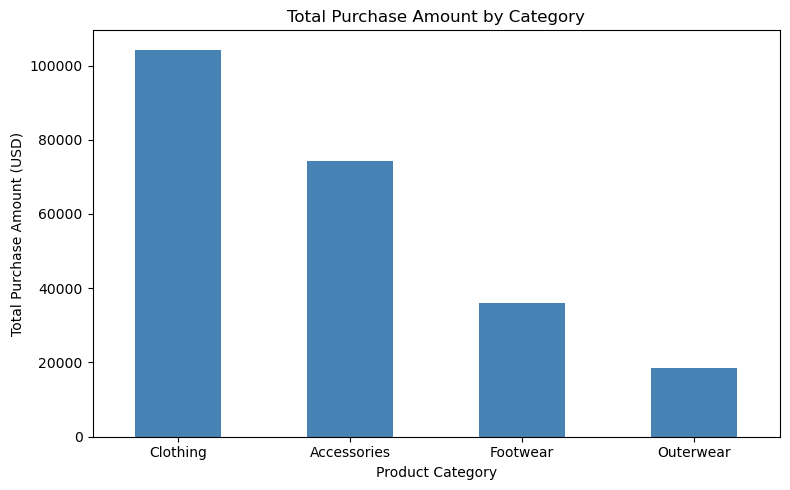

In [12]:

import matplotlib.pyplot as plt

# Total Purchase Amount by Category
category_sales.sort_values(ascending=False).plot(
    kind="bar",
    figsize=(8, 5),
    color="steelblue"
)

plt.title("Total Purchase Amount by Category")
plt.xlabel("Product Category")
plt.ylabel("Total Purchase Amount (USD)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [13]:

# Analysis 2: Average Purchase Amount by Gender
gender_avg = df.groupby("Gender")["Purchase Amount (USD)"].mean()
gender_avg.sort_values(ascending=False)


Gender
Female    60.249199
Male      59.536199
Name: Purchase Amount (USD), dtype: float64

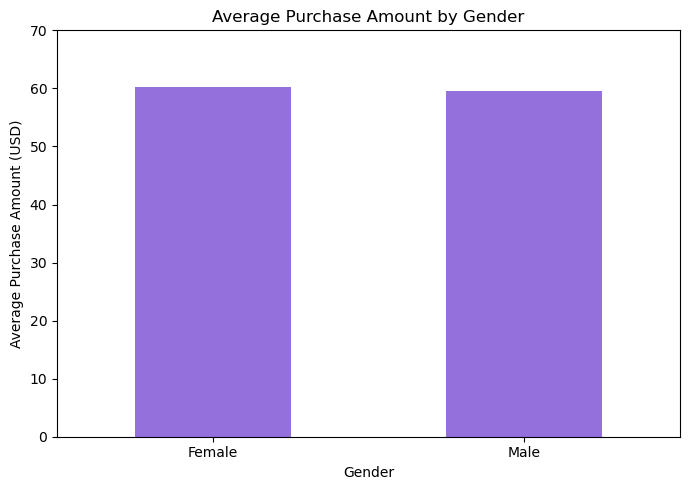

In [14]:
# Average Purchase Amount by Gender
gender_avg.sort_values(ascending=False).plot(
    kind="bar",
    figsize=(7, 5),
    color="mediumpurple"
)
plt.title("Average Purchase Amount by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Purchase Amount (USD)")
plt.xticks(rotation=0)
plt.ylim(0, 70)
plt.tight_layout()
plt.show()

In [15]:

# Analysis 3: Average Purchase Amount by Subscription Status
subscription_avg = df.groupby("Subscription Status")["Purchase Amount (USD)"].mean()
subscription_avg.sort_values(ascending=False)


Subscription Status
No     59.865121
Yes    59.491928
Name: Purchase Amount (USD), dtype: float64

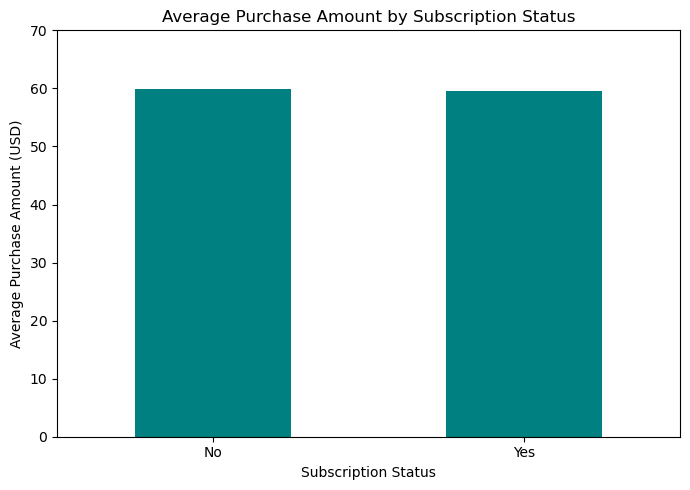

In [16]:

# Average Purchase Amount by Subscription Status
subscription_avg.sort_values(ascending=False).plot(
    kind="bar",
    figsize=(7, 5),
    color="teal"
)
plt.title("Average Purchase Amount by Subscription Status")
plt.xlabel("Subscription Status")
plt.ylabel("Average Purchase Amount (USD)")
plt.xticks(rotation=0)
plt.ylim(0, 70)
plt.tight_layout()
plt.show()


In [17]:
# Analysis 4: Total Purchase Amount by Season
season_sales = df.groupby("Season")["Purchase Amount (USD)"].sum()
season_sales.sort_values(ascending=False)


Season
Fall      60018
Spring    58679
Winter    58607
Summer    55777
Name: Purchase Amount (USD), dtype: int64

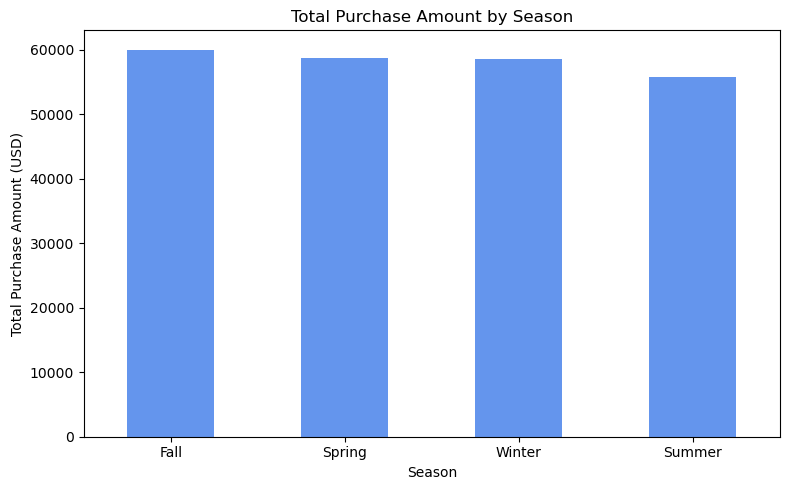

In [18]:
# Total Purchase Amount by Season
season_sales.sort_values(ascending=False).plot(
    kind="bar",
    figsize=(8, 5),
    color="cornflowerblue"
)

plt.title("Total Purchase Amount by Season")
plt.xlabel("Season")
plt.ylabel("Total Purchase Amount (USD)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



# ==========================================
# Data Quality Findings
# ==========================================

# The dataset contains 3,900 records and 19 columns.

# No missing values were found in any column.

# No fully duplicated rows were found.

# Data types were checked using df.info().
# The dataset contains 14 object columns,
# 4 integer columns, and 1 float column.

# Customer ID contains 3,900 unique values,
# indicating that each record has a unique customer ID.

# Discount Applied and Promo Code Used contain
# identical values across all 3,900 records.
# This may indicate overlapping information between
# the two columns, but it is not necessarily a data error.

# No rows needed to be removed due to missing
# values or duplicate records.

# The dataset is ready for further analysis.



## Business Insights

### Insight 1: Sales Performance by Category
Clothing generated the highest total purchase amount ($104,264), while Outerwear generated the lowest ($18,524).

This finding is supported by grouping purchase amounts by category and calculating their totals.

Clothing is an important contributor to overall sales, so management should pay attention to its inventory and product availability.

### Insight 2: Customer Subscription
Non-subscribed customers generated $170,436 in total purchases, compared with $62,645 from subscribed customers.

This finding is supported by analyzing purchase amounts based on subscription status.

Management could investigate ways to encourage more customers to subscribe and evaluate whether subscriptions improve customer loyalty.

### Insight 3: Seasonal Sales
Fall had the highest total purchase amount ($60,018), while Summer had the lowest ($55,777).
This finding is supported by comparing total purchase amounts across seasons.

Management can use these results to plan seasonal promotions and prepare inventory based on customer demand.
